In [106]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)

# Figure 2

In [107]:
def get_antilog(df_fold_change):
    df_fold_change.rename(columns={df_fold_change.columns[0]: "GeneSymbol", 
                                   df_fold_change.columns[1]: "GeneID"}, inplace=True)
    log2_fold_changes = df_fold_change['log2FoldChange']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes   
    df_fold_change = df_fold_change.rename(columns = {'log2FoldChange': 'logFC'})
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'logFC', 'Antilog_FC', 'padj']]  # 'logCPM', 
    return df_fold_change

In [109]:
spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
#spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)

mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv") 
#mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)

spalax_scar_foldchange = pd.read_csv("S.control-S.scar/S.control-S.scar_genes.csv") 
#spalax_scar_foldchange = spalax_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_scar_foldchange = get_antilog(spalax_scar_foldchange)

mouse_scar_foldchange = pd.read_csv("MM.control-M.scar/MM.control-M.scar_genes.csv") 
#mouse_scar_foldchange = mouse_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_scar_foldchange = get_antilog(mouse_scar_foldchange)

In [110]:
spalax_wound_up_count = len(spalax_wound_foldchange[spalax_wound_foldchange['logFC'] > 0])
spalax_wound_down_count = len(spalax_wound_foldchange[spalax_wound_foldchange['logFC'] < 0])
spalax_scar_up_count = len(spalax_scar_foldchange[spalax_scar_foldchange['logFC'] > 0])
spalax_scar_down_count = len(spalax_scar_foldchange[spalax_scar_foldchange['logFC'] < 0])

mouse_wound_up_count = len(mouse_wound_foldchange[mouse_wound_foldchange['logFC'] > 0])
mouse_wound_down_count = len(mouse_wound_foldchange[mouse_wound_foldchange['logFC'] < 0])
mouse_scar_up_count = len(mouse_scar_foldchange[mouse_scar_foldchange['logFC']> 0])
mouse_scar_down_count = len(mouse_scar_foldchange[mouse_scar_foldchange['logFC'] < 0])

In [111]:
print(spalax_wound_up_count + spalax_wound_down_count)
print(spalax_scar_up_count + spalax_scar_down_count)
print(mouse_wound_up_count + mouse_wound_down_count)
print(mouse_scar_up_count + mouse_scar_down_count)

458
529
1041
1454


In [112]:
print("Spalax wound - Up:", spalax_wound_up_count)
print("Spalax wound - Down:", spalax_wound_down_count)

print("Spalax scar - Up:", spalax_scar_up_count)
print("Spalax scar - Down:", spalax_scar_down_count)

print("Mouse wound - Up:", mouse_wound_up_count)
print("Mouse wound - Down:", mouse_wound_down_count)

print("Mouse scar - Up:", mouse_scar_up_count)
print("Mouse scar - Down:", mouse_scar_down_count)

Spalax wound - Up: 236
Spalax wound - Down: 222
Spalax scar - Up: 425
Spalax scar - Down: 104
Mouse wound - Up: 355
Mouse wound - Down: 686
Mouse scar - Up: 908
Mouse scar - Down: 546


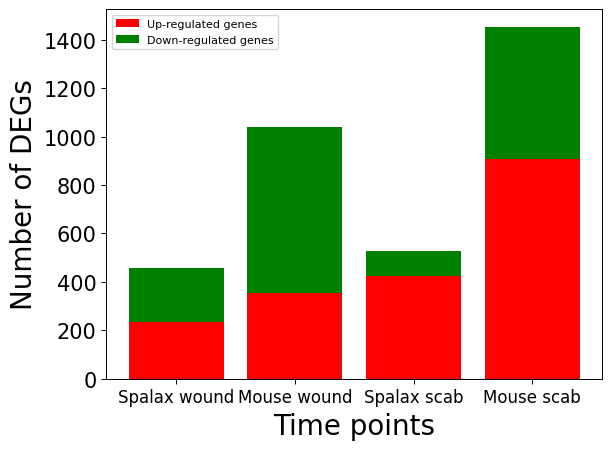

In [113]:
# create data
x = ['Spalax wound', 'Mouse wound', 'Spalax scab', 'Mouse scab']
y1 = np.array([spalax_wound_up_count, mouse_wound_up_count, spalax_scar_up_count, mouse_scar_up_count ])
y2 = np.array([spalax_wound_down_count, mouse_wound_down_count, spalax_scar_down_count, mouse_scar_down_count])

# plot bars in stack manner
plt.bar(x, y1, color='r')
plt.bar(x, y2, bottom=y1, color='g')
plt.xlabel("Time points", fontsize = 20)
plt.ylabel("Number of DEGs", fontsize = 20)
plt.legend(["Up-regulated genes", "Down-regulated genes"], fontsize = 8)
#plt.title("up/down-regulated DEGs in both species", fontsize = 20)
plt.xticks(fontsize=12)
plt.yticks(fontsize=15)
plt.savefig('upregulated_downregulated.jpg', format='jpeg', dpi=300, bbox_inches='tight')
plt.show()

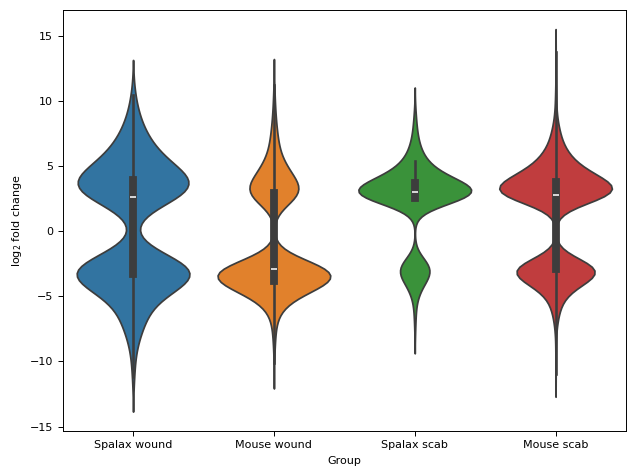

In [114]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

colors = {
    'Spalax wound': '#1f77b4',  # blue
    'Spalax scab': '#2ca02c',   # green
    'Mouse wound': '#ff7f0e',   # orange
    'Mouse scab': '#d62728'     # red
}

# Build one dataframe for all 4 groups
violin_df = pd.DataFrame({
    'logFC': pd.concat([
        spalax_wound_foldchange['logFC'],        
        mouse_wound_foldchange['logFC'],
        spalax_scar_foldchange['logFC'],
        mouse_scar_foldchange['logFC']
    ], ignore_index=True),
    'Group': ['Spalax wound'] * len(spalax_wound_foldchange)
           + ['Mouse wound'] * len(mouse_wound_foldchange)
           + ['Spalax scab'] * len(spalax_scar_foldchange)
           + ['Mouse scab'] * len(mouse_scar_foldchange)
})

# Plot
ax = sns.violinplot(data=violin_df, x='Group', y='logFC', palette=colors)
plt.xlabel("Group")
plt.ylabel("log$_2$ fold change")
plt.tight_layout()  # avoids labels getting cut off at high DPI

plt.savefig("C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/data_for_figure/python_figures/logFC_violinplot.png", dpi=600, bbox_inches="tight")
plt.show()


# Figure 3

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

def filter_by_qvalue(df: pd.DataFrame, threshold: float = 0.05) -> pd.DataFrame:
    """
    Filters a DataFrame to keep only rows where 'qvalue' is less than the given threshold.

    Parameters:
        df (pd.DataFrame): Input DataFrame with a 'qvalue' column.
        threshold (float): Threshold for filtering. Default is 0.05.

    Returns:
        pd.DataFrame: Filtered DataFrame.
    """
    if 'qvalue' not in df.columns:
        raise ValueError("The DataFrame must contain a 'qvalue' column.")
    
    return df[df['qvalue'] < threshold]

def filter_scab_q_value(df_scab, df_wound):
    return df_scab[
    df_scab['Description'].isin(
        list(df_wound.Description[0:20])
    )][['Description', 'qvalue']]


def reindex_df(df1, df2):
    # Set Description as index in df2
    df2_indexed = df2.set_index('Description')

    # Reindex df2 to match the order of df1['Description'], and fill missing q-values with 0
    df2_sorted = df2_indexed.reindex(df1['Description']).fillna(0).reset_index()

    # Ensure the column is named correctly (in case of case or spacing issues)
    df2_sorted.rename(columns={'qvalue': 'qvalue'}, inplace=True)  # optional, if name is inconsistent

    # Result: df2_sorted now has the same Description order as df1, with 0 qvalue where missing
    return df2_sorted

def plot_pathway_intensity(ax, timepoint, title, color):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue', 'Count']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    n_display = len(pathways)
    y_pos = np.arange(n_display)[::-1] + (20 - n_display)  # Shift bars to top of 10-slot space

    ax.barh(y_pos, pathways.qvalue, align='center', color=color, height=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 40)
    ax.set_ylim(-0.5, 20.5)  # Reserve space for 10
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)
   
def plot_pathway_intensity(ax, timepoint, title, color, panel_label):

    pathways = timepoint.iloc[0:20][['Description', 'qvalue']].copy()

    pathways['Description'] = [
        p.split(' - Mus musculus (house mouse)')[0]
        for p in pathways['Description'].values
    ]

    pathways['qvalue'] = -np.log(pathways['qvalue'])

    # Maximum number of pathway slots across all panels
    n_slots = 20

    n_pathways = len(pathways)

    # Define the vertical space occupied by the bars
    # For 20 pathways: use the full available space
    # For fewer pathways: keep them clustered near the top
    if n_pathways == n_slots:
        y_pos = np.arange(n_slots - 1, -1, -1)

    else:
        cluster_height = 4

        y_pos = np.linspace(
            n_slots - 1,
            n_slots - cluster_height,
            n_pathways
        )

    # Plot bars with a fixed thickness
    ax.barh(
        y_pos,
        pathways['qvalue'],
        height=0.8,
        align='center',
        color=color
    )

    # Labels
    ax.set_yticks(y_pos)
    ax.set_yticklabels(
        pathways['Description'],
        fontsize=15
    )

    # Keep the same vertical scale across all panels
    ax.set_ylim(-0.5, n_slots - 0.5)

    # Formatting
    ax.set_title(
        title,
        fontsize=15
    )

    ax.set_xlim(0, 55)

    ax.set_xlabel(
        '-log(q-value)',
        fontsize=20
    )

    ax.tick_params(
        axis='x',
        labelsize=15
    )

    # Panel label
    ax.text(
        -0.45,
        1.08,
        panel_label,
        transform=ax.transAxes,
        fontsize=22,
        fontweight='bold',
        va='top',
        ha='left'
    )



### BP & Pathway data loading

In [117]:
# BP
spalax_wound_bp = pd.read_csv("../entrezID/S.control-S.wound/GeneOntologyBP.csv")
spalax_wound_bp = spalax_wound_bp.drop(columns = ['Unnamed: 0'])
spalax_wound_bp = filter_by_qvalue(spalax_wound_bp)
spalax_scab_bp = pd.read_csv("../entrezID/S.control-S.scar/GeneOntologyBP.csv")
spalax_scab_bp = spalax_scab_bp.drop(columns = ['Unnamed: 0'])
spalax_scab_bp = filter_by_qvalue(spalax_scab_bp)

mouse_wound_bp = pd.read_csv("../entrezID/MM.control-M.wound/GeneOntologyBP.csv")
mouse_wound_bp = mouse_wound_bp.drop(columns = ['Unnamed: 0'])
mouse_wound_bp = filter_by_qvalue(mouse_wound_bp)
mouse_scab_bp = pd.read_csv("../entrezID/MM.control-M.scar/GeneOntologyBP.csv")
mouse_scab_bp = mouse_scab_bp.drop(columns = ['Unnamed: 0'])
mouse_scab_bp = filter_by_qvalue(mouse_scab_bp)

# Pathway
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/Kegg_pathway.csv.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])
spalax_wound_pathways = filter_by_qvalue(spalax_wound_pathways)
spalax_scab_pathways = pd.read_csv("../entrezID/S.control-S.scar/Kegg_pathway.csv.csv")
spalax_scab_pathways = spalax_scab_pathways.drop(columns = ['Unnamed: 0'])
spalax_scab_pathways = filter_by_qvalue(spalax_scab_pathways)

# ---------------------------------
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/Kegg_pathway_Mouse.csv.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])
mouse_wound_pathways = filter_by_qvalue(mouse_wound_pathways)
mouse_scab_pathways = pd.read_csv("../entrezID/MM.control-M.scar/Kegg_pathway.csv.csv")
mouse_scab_pathways = mouse_scab_pathways.drop(columns = ['Unnamed: 0'])
mouse_scab_pathways = filter_by_qvalue(mouse_scab_pathways)

### Combine both plots above

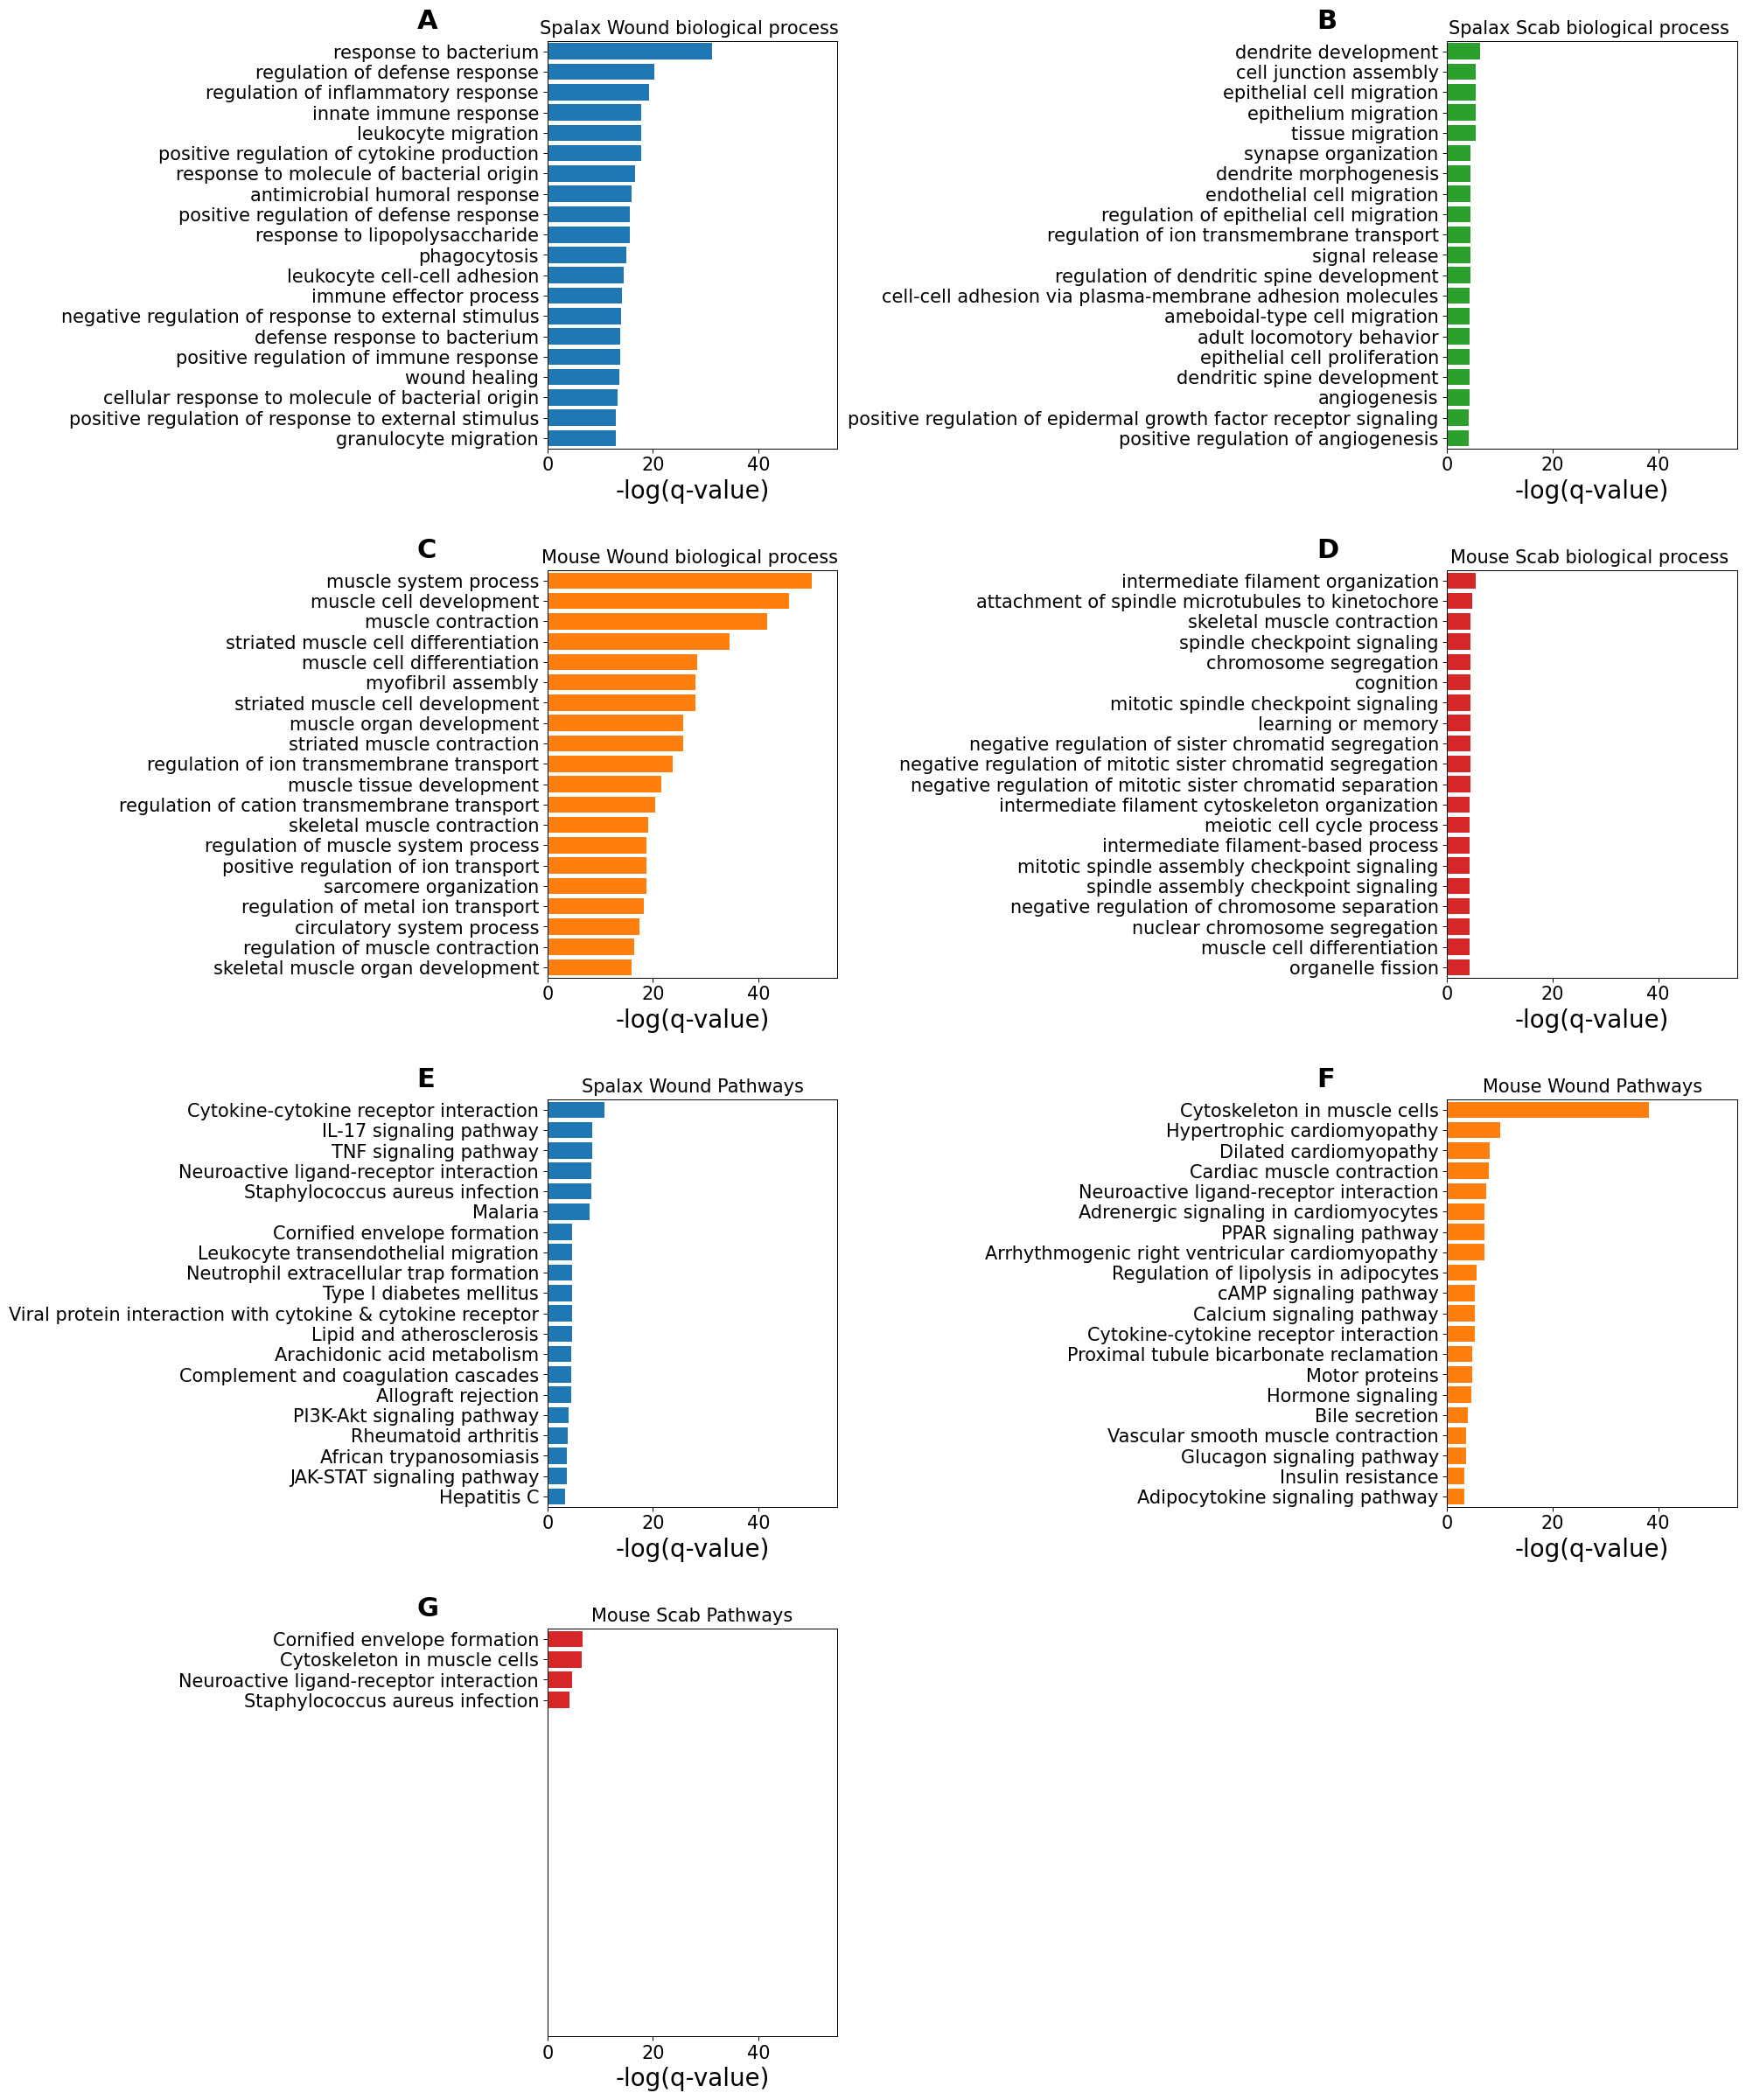

In [ ]:
# Create a 2x2 subplot figure
fig, axs = plt.subplots(4, 2, figsize=(20, 24))

# Plot each pathway intensity on its respective subplot
spalax_scab_bp.loc[18, "Description"] = "positive regulation of epidermal growth factor receptor signaling"
plot_pathway_intensity(axs[0, 0], spalax_wound_bp, 'Spalax Wound biological process ', colors['Spalax wound'], 'A')
plot_pathway_intensity(axs[0, 1], spalax_scab_bp, 'Spalax Scab biological process ', colors['Spalax scab'], 'B')
plot_pathway_intensity(axs[1, 0], mouse_wound_bp, 'Mouse Wound biological process ', colors['Mouse wound'], 'C')
plot_pathway_intensity(axs[1, 1], mouse_scab_bp, 'Mouse Scab biological process ', colors['Mouse scab'], 'D')

# Plot each pathway intensity on its respective subplot
spalax_wound_pathways.loc[10, "Description"] = "Viral protein interaction with cytokine & cytokine receptor"
plot_pathway_intensity(axs[2, 0], spalax_wound_pathways, 'Spalax Wound Pathways', colors['Spalax wound'], 'E')
plot_pathway_intensity(axs[2, 1], mouse_wound_pathways, 'Mouse Wound Pathways', colors['Mouse wound'], 'F')
plot_pathway_intensity(axs[3, 0], mouse_scab_pathways, 'Mouse Scab Pathways', colors['Mouse scab'], 'G')
fig.delaxes(axs[3, 1])


# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows
plt.savefig('C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/data_for_figure/python_figures/GO_Pathway_across_stages.jpg', dpi=300)

# Show the plot
plt.show()

# Figure 4

Number of common genes: 13


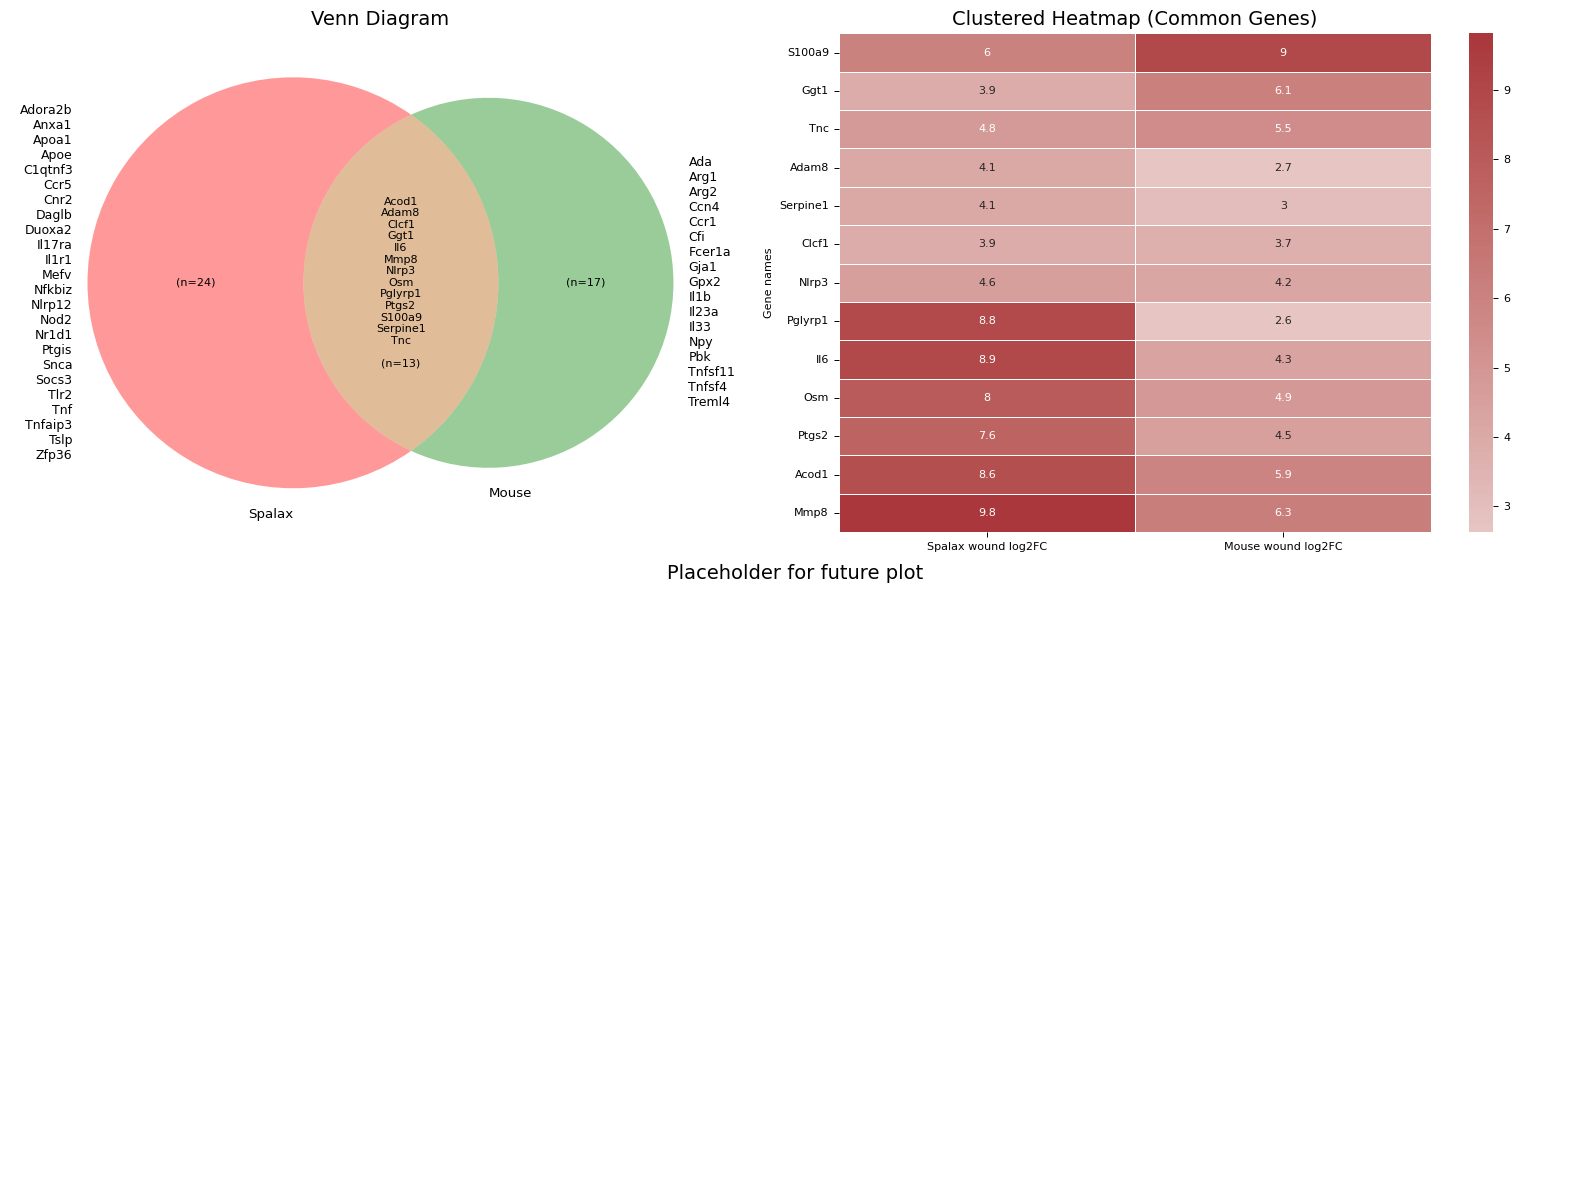

In [120]:
import matplotlib.gridspec as gridspec
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from scipy.cluster.hierarchy import linkage, leaves_list

path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)

# "regulation of inflammatory response" biological process genes in both species (See paper for details)
# Spalax
a = "Acod1/Adam8/Adora2b/Anxa1/Apoa1/Apoe/C1qtnf3/Ccr5/Clcf1/Cnr2/Daglb/Duoxa2/Ggt1/Il17ra/Il1r1/Il6/Mefv/Mmp8/Nfkbiz/Nlrp12/Nlrp3/Nod2/Nr1d1/Osm/Pglyrp1/Ptgis/Ptgs2/S100a9/Serpine1/Snca/Socs3/Tlr2/Tnc/Tnf/Tnfaip3/Tslp/Zfp36".split("/")
# Mouse
b = "Acod1/Ada/Adam8/Arg1/Arg2/Ccr1/Cfi/Clcf1/Fcer1a/Ggt1/Gja1/Gpx2/Il1b/Il23a/Il33/Il6/Mmp8/Nlrp3/Npy/Osm/Pbk/Pglyrp1/Ptgs2/S100a9/Serpine1/Tnc/Tnfsf11/Tnfsf4/Treml4/Ccn4".split("/")

# Find intersection
a = set(a)
b = set(b)
common_genes = a & b
unique_a = a - b
unique_b = b - a

print(f"Number of common genes: {len(common_genes)}")

# Load data
df1 = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
df2 = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv")

# Keep only common genes
df1 = df1[df1['genename'].isin(common_genes)][['genename','log2FoldChange']]
df2 = df2[df2['genename'].isin(common_genes)][['genename','log2FoldChange']]

df1.rename(columns={'log2FoldChange': 'Spalax wound log2FC'}, inplace=True)
df2.rename(columns={'log2FoldChange': 'Mouse wound log2FC'}, inplace=True)

df_merge = pd.merge(df1, df2, on='genename', how='outer').set_index('genename')

# Cluster rows (genes) using hierarchical clustering
link = linkage(df_merge.fillna(0), method='average', metric='euclidean')
gene_order = leaves_list(link)
df_merge = df_merge.iloc[gene_order]

# Plot composite figure
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1.2])  # top row smaller

# --- Left: Venn diagram ---
ax1 = fig.add_subplot(gs[0, 0])
venn = venn2([a, b], set_labels=("Spalax", "Mouse"), ax=ax1)

# Inside labels: counts only
if venn.get_label_by_id("10"):
    venn.get_label_by_id("10").set_text(f"(n={len(unique_a)})")
if venn.get_label_by_id("01"):
    venn.get_label_by_id("01").set_text(f"(n={len(unique_b)})")
if venn.get_label_by_id("11"):
    venn.get_label_by_id("11").set_text("\n".join(sorted(common_genes)) + f"\n\n(n={len(common_genes)})")

# Place unique genes outside circles
c0 = venn.get_circle_center(0)
c1 = venn.get_circle_center(1)

ax1.annotate("\n".join(sorted(unique_a)),
             xy=(c0.x, c0.y),
             xytext=(-0.7, 0), ha='right', va='center',
             fontsize=9)

ax1.annotate("\n".join(sorted(unique_b)),
             xy=(c1.x, c1.y),
             xytext=(0.7, 0), ha='left', va='center',
             fontsize=9)

ax1.set_title("Venn Diagram", fontsize=14)

# --- Top right: Heatmap ---
ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(
    df_merge,
    cmap="vlag",
    center=0,
    annot=True,
    linewidths=0.5,
    ax=ax2
)
ax2.set_ylabel("Gene names")
ax2.set_title("Clustered Heatmap (Common Genes)", fontsize=14)

# --- Bottom row: empty placeholder ---
ax3 = fig.add_subplot(gs[1, :])
ax3.axis("off")
ax3.set_title("Placeholder for future plot", fontsize=14)

fig.savefig("gene_venn_heatmap.png", dpi=300, bbox_inches='tight')
fig.savefig("gene_venn_heatmap.pdf", bbox_inches='tight')
plt.tight_layout()
plt.show()


# Figure 5


[load_enrichment] GeneOntologyBP_Spalax_wound.csv  shape=(602, 9)
  columns: ['ID', 'Description', 'GeneRatio', 'BgRatio', 'pvalue', 'p.adjust', 'qvalue', 'geneID', 'Count']
  q-value col  → 'qvalue'
  gene-list col → 'geneID'

[load_enrichment] Kegg_pathway_Spalax_wound.csv  shape=(21, 10)
  columns: ['ID', 'Description', 'GeneRatio', 'BgRatio', 'pvalue', 'p.adjust', 'qvalue', 'geneID', 'Count', 'gene_names']
  q-value col  → 'qvalue'
  gene-list col → 'geneID'

[load_expression] MM.control-M.scar_genes.csv  shape=(1454, 4)  cols=['Unnamed: 0', 'Unnamed: 1', 'log2FoldChange', 'padj']
  LFC col → 'log2FoldChange'

[load_expression] MM.control-M.wound_genes.csv  shape=(1041, 5)  cols=['genename', 'id', 'log2FoldChange', 'padj', 'Abs_log2FC']
  gene-symbol col → 'genename'
  LFC col → 'log2FoldChange'

[load_expression] S.control-S.scar_genes.csv  shape=(529, 4)  cols=['Unnamed: 0', 'Unnamed: 1', 'log2FoldChange', 'padj']
  LFC col → 'log2FoldChange'

[load_expression] S.control-S.wound

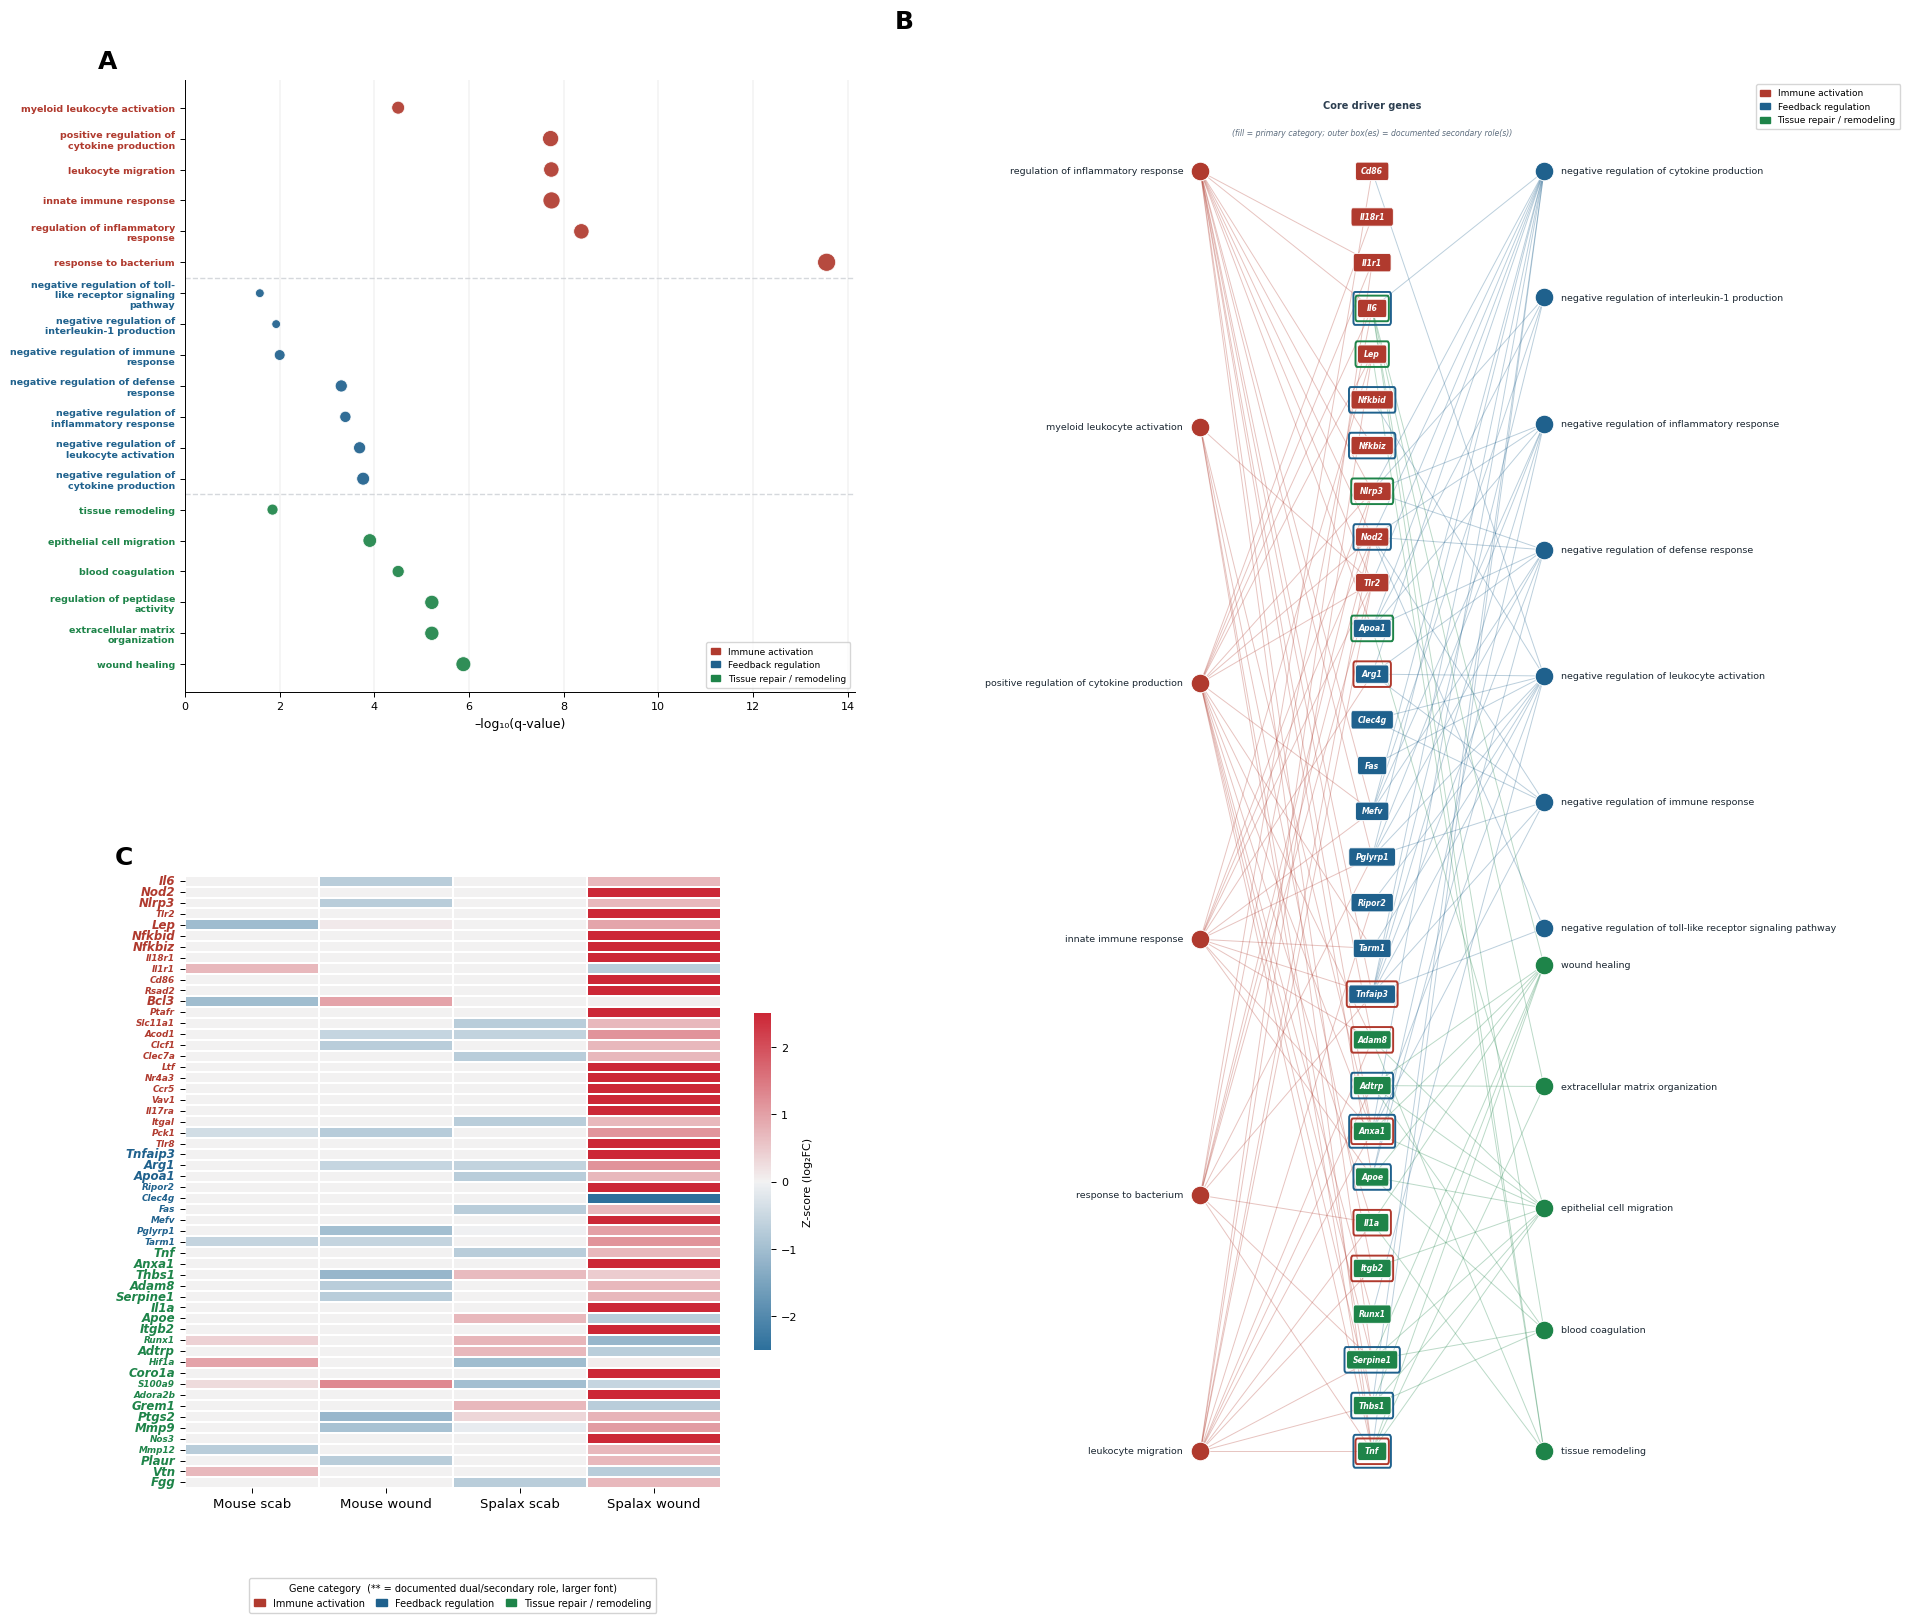


Done.


In [ ]:
"""
Figure 5 – Coupled inflammatory activation and feedback regulation
             in Spalax wound tissue

Run from the same directory as this file; data lives in ./data_for_figure/
Outputs: Figure5_conceptual_spalax_wound.{png,pdf,svg}
"""

import warnings
warnings.filterwarnings("ignore")

import re
import sys
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import networkx as nx

# ─── Paths ────────────────────────────────────────────────────────────────────
DATA_DIR = Path('C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/data_for_figure')
OUT_STEM = DATA_DIR / "Figure5_ABC"

# ─── Global color palette (consistent across all panels) ─────────────────────
COLORS = {
    "immune_activation":   "#B03A2E",   # deep red
    "feedback_regulation": "#1F618D",   # steel blue
    "tissue_repair":       "#1E8449",   # forest green
    "other":               "#7F8C8D",   # grey
}
CAT_LABELS = {
    "immune_activation":   "Immune activation",
    "feedback_regulation": "Feedback regulation",
    "tissue_repair":       "Tissue repair / remodeling",
    "other":               "Other",
}

# NOTE: the Entrez-ID-based SUPPLEMENTARY_GENE_MAP that used to live here
# has been removed. The expression files are indexed by gene symbol
# ('genename'), not Entrez ID, so load_expression_files() now looks genes
# up directly by (lowercased) symbol. See load_expression_files() below.


# ═════════════════════════════════════════════════════════════════════════════
#  1. load_enrichment
# ═════════════════════════════════════════════════════════════════════════════
def load_enrichment(filepath: Path) -> pd.DataFrame:
    """Load a clusterProfiler enrichment CSV with auto-detected columns."""
    df = pd.read_csv(filepath, index_col=0)
    print(f"\n[load_enrichment] {filepath.name}  shape={df.shape}")
    print(f"  columns: {list(df.columns)}")

    # ── q-value ──────────────────────────────────────────────────────────────
    for col in ("qvalue", "q_value", "q.value", "p.adjust", "padj", "FDR"):
        if col in df.columns:
            df["_qval"] = pd.to_numeric(df[col], errors="coerce")
            print(f"  q-value col  → '{col}'")
            break
    else:
        raise ValueError(
            f"No q-value column in {filepath.name}. "
            f"Found: {list(df.columns)}"
        )

    # ── description ──────────────────────────────────────────────────────────
    for col in ("Description", "description", "term", "pathway", "Term"):
        if col in df.columns:
            df["_desc"] = df[col].astype(str)
            break
    else:
        df["_desc"] = df.index.astype(str)

    # Strip " - Mus musculus (house mouse)" from KEGG descriptions
    df["_desc"] = df["_desc"].str.replace(
        r"\s*-\s*Mus musculus.*$", "", regex=True
    ).str.strip()

    # ── gene list ─────────────────────────────────────────────────────────────
    for col in ("geneID", "gene_names", "genes", "Genes", "geneList"):
        if col in df.columns:
            df["_genes"] = df[col].astype(str)
            print(f"  gene-list col → '{col}'")
            break
    else:
        df["_genes"] = ""

    # ── count & ratio ─────────────────────────────────────────────────────────
    for col in ("Count", "count", "GeneCount"):
        if col in df.columns:
            df["_count"] = pd.to_numeric(df[col], errors="coerce")
            break
    else:
        df["_count"] = np.nan

    for col in ("GeneRatio", "generatio", "gene_ratio"):
        if col in df.columns:
            df["_ratio"] = df[col].apply(
                lambda x: eval(str(x)) if "/" in str(x) else float(x)
            )
            break
    else:
        df["_ratio"] = np.nan

    df["-log10q"] = -np.log10(df["_qval"].clip(lower=1e-300))
    return df


# ═════════════════════════════════════════════════════════════════════════════
#  2. parse_gene_list
# ═════════════════════════════════════════════════════════════════════════════
def parse_gene_list(gene_str: str) -> list:
    """Split a gene string on '/', ';', or ',' and return clean symbols."""
    if pd.isna(gene_str) or str(gene_str).strip() in ("", "nan"):
        return []
    return [
        g.strip()
        for g in re.split(r"[/;,]", str(gene_str))
        if g.strip() and g.strip().lower() != "nan"
    ]


# ═════════════════════════════════════════════════════════════════════════════
#  3. assign_go_category
# ═════════════════════════════════════════════════════════════════════════════
def assign_go_category(description: str) -> str:
    """Map a GO / KEGG description string to a biological category key."""
    d = description.lower()

    feedback_kw = [
        "negative regulation", "neg. regulation", "inhibition",
        "suppression", "feedback",
    ]
    repair_kw = [
        "wound healing", "tissue remodel", "extracellular matrix",
        "matrix organization", "proteolysis", "cell migration",
        "angiogenesis", "ecm-receptor", "coagulation", "arachidonic",
        "lipid and athero", "repair", "peptidase activity",
        "response to external stimulus",
    ]
    immune_kw = [
        "inflammatory", "immune", "cytokine", "leukocyte", "bacterium",
        "innate", "toll-like", "tlr", "nlrp", "nf-kb", "il-17", "tnf",
        "jak-stat", "chemokine", "interferon", "neutrophil", "monocyte",
        "macrophage", "activation", "defense", "pathogen",
        "cytokine receptor", "viral", "infection", "malaria",
        "staphylococcus", "complement", "neuroactive", "allograft",
        "rheumatoid", "diabetes", "hepatitis", "trypanosomiasis",
    ]

    if any(k in d for k in feedback_kw):
        return "feedback_regulation"
    if any(k in d for k in repair_kw):
        return "tissue_repair"
    if any(k in d for k in immune_kw):
        return "immune_activation"
    return "other"


# ═════════════════════════════════════════════════════════════════════════════
#  4. Gene → functional-module assignment
# ═════════════════════════════════════════════════════════════════════════════
# NOT a keyword heuristic. These 56 genes are the statistically-significant
# hub genes from an exact Poisson-binomial recurrence test (genes appearing
# in significantly more enriched GO Biological Process terms than expected
# by chance, given each term's size), run on a curated subset of the 602
# significant Spalax-wound GO BP terms restricted to immune-activation,
# feedback-regulation, and tissue-repair-relevant biology (keyword dictionary
# includes cell adhesion / epithelial proliferation terms as of this version).
# Each gene's PRIMARY category is simply whichever category's term pool it
# is proportionally most represented in — no manual override is applied
# anywhere, including for Tnf, which previously required one: with the
# expanded repair keyword set, Tnf's category proportions resolved to a
# clear top category (56.2% tissue_repair) rather than the near-tie seen
# with the earlier, narrower keyword set (49.0/42.3/39.0).
#
# GENE_SECONDARY lists EVERY additional category (beyond primary) at >=15%
# of that category's own term pool — genes can have zero, one, or two
# entries (e.g. Tnf: tissue_repair primary, with both immune_activation and
# feedback_regulation as documented secondary roles). Two entries (Bcl3,
# Nfkbiz) are literature-flagged rather than data-driven: both are
# established atypical-IkB NF-kB feedback regulators whose GO-term co-
# occurrence in this dataset did not independently clear the 15% threshold.

GENE_PRIMARY = {
    "Tnfaip3": "feedback_regulation",
    "Arg1": "feedback_regulation",
    "Apoa1": "feedback_regulation",
    "Ripor2": "feedback_regulation",
    "Clec4g": "feedback_regulation",
    "Fas": "feedback_regulation",
    "Mefv": "feedback_regulation",
    "Pglyrp1": "feedback_regulation",
    "Tarm1": "feedback_regulation",
    "Il6": "immune_activation",
    "Nod2": "immune_activation",
    "Nlrp3": "immune_activation",
    "Tlr2": "immune_activation",
    "Lep": "immune_activation",
    "Nfkbid": "immune_activation",
    "Nfkbiz": "immune_activation",
    "Il18r1": "immune_activation",
    "Il1r1": "immune_activation",
    "Cd86": "immune_activation",
    "Rsad2": "immune_activation",
    "Bcl3": "immune_activation",
    "Ptafr": "immune_activation",
    "Slc11a1": "immune_activation",
    "Acod1": "immune_activation",
    "Clcf1": "immune_activation",
    "Clec7a": "immune_activation",
    "Ltf": "immune_activation",
    "Nr4a3": "immune_activation",
    "Ccr5": "immune_activation",
    "Vav1": "immune_activation",
    "Il17ra": "immune_activation",
    "Itgal": "immune_activation",
    "Pck1": "immune_activation",
    "Tlr8": "immune_activation",
    "Tnf": "tissue_repair",
    "Anxa1": "tissue_repair",
    "Thbs1": "tissue_repair",
    "Adam8": "tissue_repair",
    "Serpine1": "tissue_repair",
    "Il1a": "tissue_repair",
    "Apoe": "tissue_repair",
    "Itgb2": "tissue_repair",
    "Runx1": "tissue_repair",
    "Adtrp": "tissue_repair",
    "Hif1a": "tissue_repair",
    "Coro1a": "tissue_repair",
    "S100a9": "tissue_repair",
    "Adora2b": "tissue_repair",
    "Grem1": "tissue_repair",
    "Ptgs2": "tissue_repair",
    "Mmp9": "tissue_repair",
    "Nos3": "tissue_repair",
    "Mmp12": "tissue_repair",
    "Plaur": "tissue_repair",
    "Vtn": "tissue_repair",
    "Fgg": "tissue_repair",
}

GENE_SECONDARY = {  # list of categories, in addition to primary, at >=15pct of that
                    # category's own term pool (or literature-flagged override)
    "Tnfaip3": ["immune_activation"],
    "Arg1": ["immune_activation"],
    "Apoa1": ["tissue_repair"],
    "Il6": ["tissue_repair", "feedback_regulation"],
    "Nod2": ["feedback_regulation"],
    "Nlrp3": ["tissue_repair"],
    "Lep": ["tissue_repair"],
    "Nfkbid": ["feedback_regulation"],
    "Nfkbiz": ["feedback_regulation"],
    "Bcl3": ["feedback_regulation"],
    "Tnf": ["immune_activation", "feedback_regulation"],
    "Anxa1": ["immune_activation", "feedback_regulation"],
    "Thbs1": ["feedback_regulation"],
    "Adam8": ["immune_activation"],
    "Serpine1": ["feedback_regulation"],
    "Il1a": ["immune_activation"],
    "Apoe": ["feedback_regulation"],
    "Itgb2": ["immune_activation"],
    "Adtrp": ["feedback_regulation"],
    "Coro1a": ["immune_activation"],
    "Grem1": ["feedback_regulation"],
    "Ptgs2": ["feedback_regulation"],
    "Mmp9": ["feedback_regulation"],
    "Plaur": ["feedback_regulation"],
    "Vtn": ["feedback_regulation"],
    "Fgg": ["feedback_regulation"],
}

GENE_N_TERMS = {  # recurrence significance (num. curated relevant GO terms), for ranking only
    "Tnfaip3": 75,
    "Arg1": 67,
    "Apoa1": 46,
    "Ripor2": 42,
    "Clec4g": 41,
    "Fas": 32,
    "Mefv": 31,
    "Pglyrp1": 31,
    "Tarm1": 31,
    "Il6": 167,
    "Nod2": 131,
    "Nlrp3": 108,
    "Tlr2": 84,
    "Lep": 72,
    "Nfkbid": 61,
    "Nfkbiz": 54,
    "Il18r1": 51,
    "Il1r1": 51,
    "Cd86": 50,
    "Rsad2": 50,
    "Bcl3": 45,
    "Ptafr": 42,
    "Slc11a1": 42,
    "Acod1": 39,
    "Clcf1": 39,
    "Clec7a": 39,
    "Ltf": 39,
    "Nr4a3": 39,
    "Ccr5": 35,
    "Vav1": 31,
    "Il17ra": 30,
    "Itgal": 30,
    "Pck1": 30,
    "Tlr8": 30,
    "Tnf": 144,
    "Anxa1": 118,
    "Thbs1": 85,
    "Adam8": 68,
    "Serpine1": 67,
    "Il1a": 58,
    "Apoe": 48,
    "Itgb2": 48,
    "Runx1": 48,
    "Adtrp": 44,
    "Hif1a": 44,
    "Coro1a": 43,
    "S100a9": 41,
    "Adora2b": 40,
    "Grem1": 37,
    "Ptgs2": 37,
    "Mmp9": 34,
    "Nos3": 33,
    "Mmp12": 31,
    "Plaur": 31,
    "Vtn": 31,
    "Fgg": 30,
}


def assign_gene_module(gene: str) -> str:
    """Primary functional module for a gene symbol (falls back to 'other')."""
    return GENE_PRIMARY.get(gene, "other")


def top_genes_per_category(n_per_category=10):
    """
    Select the top-N most recurrence-significant genes per functional
    category (or all of them, if a category has fewer than N).
    """
    selected = []
    for cat in ("immune_activation", "feedback_regulation", "tissue_repair"):
        cat_genes = [g for g, c in GENE_PRIMARY.items() if c == cat]
        cat_genes.sort(key=lambda g: (-GENE_N_TERMS.get(g, 0), g))
        selected.extend(cat_genes[:n_per_category])
    return selected


# ═════════════════════════════════════════════════════════════════════════════
#  5. plot_go_enrichment  (Panel A)
# ═════════════════════════════════════════════════════════════════════════════
def plot_go_enrichment(ax: plt.Axes, go_df: pd.DataFrame) -> None:
    """
    Horizontal dot plot with three explicit section groups:
      Immune activation | Feedback regulation | Tissue repair / remodeling
    Point size = gene count; x-axis = –log10(q-value).
    """
    # ── Explicit term selections per section ─────────────────────────────────
    # Each list = partial patterns; first match wins (case-insensitive search)
    SECTIONS = {
        "immune_activation": [
            "inflammatory response",
            "leukocyte activation",
            "cytokine production",
            "innate immune response",
            "response to bacterium",
            "leukocyte migration",
            "neutrophil activation",
        ],
        "feedback_regulation": [
            "negative regulation of cytokine production",
            "negative regulation of inflammatory response",
            "negative regulation of defense response",
            "negative regulation of nf-kb",
            "negative regulation of interleukin-1 production",
            "negative regulation of leukocyte activation",
            "negative regulation of immune response",
            "negative regulation of toll-like receptor",
        ],
        "tissue_repair": [
            "wound healing",
            "extracellular matrix organization",
            "cell migration",
            "blood coagulation",
            "tissue remodeling",
            "regulation of peptidase activity",
        ],
    }

    desc_lower = go_df["_desc"].str.lower()

    def pick_terms(patterns, n_max=8):
        picked, seen = [], set()
        for pat in patterns:
            hits = desc_lower[desc_lower.str.contains(pat, regex=False)]
            # Among hits take the one with the best q-value
            hits_sorted = go_df.loc[hits.index].sort_values("_qval")
            for idx in hits_sorted.index:
                if idx not in seen and len(picked) < n_max:
                    picked.append(idx)
                    seen.add(idx)
                    break
        return picked

    blocks = []
    for cat_key, patterns in SECTIONS.items():
        idxs = pick_terms(patterns)
        sub = go_df.loc[idxs].copy()
        sub["category"] = cat_key
        sub["_section_order"] = list(SECTIONS.keys()).index(cat_key)
        blocks.append(sub)

    df_plot = pd.concat(blocks)
    # Sort: section_order DESCENDING so immune_activation (0) gets the highest
    # y positions and appears at the TOP of the plot (repair at bottom).
    df_plot = df_plot.sort_values(
        ["_section_order", "_qval"], ascending=[False, True]
    ).reset_index(drop=False)

    n = len(df_plot)
    ROW_SPACING = 1.7   # extra vertical room so wrapped multi-line labels don't collide
    y_pos = np.arange(n) * ROW_SPACING
    node_colors = [COLORS[c] for c in df_plot["category"]]
    cnt = df_plot["_count"].fillna(10).astype(float)
    cnt_range = max(cnt.max() - cnt.min(), 1)
    sizes = 40 + 130 * (cnt - cnt.min()) / cnt_range

    ax.scatter(df_plot["-log10q"], y_pos, c=node_colors, s=sizes,
               zorder=3, edgecolors="white", linewidths=0.6, alpha=0.92)

    labels = [textwrap.fill(d, width=30) for d in df_plot["_desc"]]
    ax.set_yticks(y_pos)
    # ax.set_yticklabels(labels, fontsize=7.2)
    yticklabels = ax.set_yticklabels(
    labels,
    fontsize=6.8
    )

    for tick, cat in zip(yticklabels, df_plot["category"]):
        tick.set_color(COLORS[cat])
        tick.set_fontweight("bold")

    ax.set_xlabel("–log₁₀(q-value)", fontsize=9)

    # Section order in plot (bottom → top): repair, feedback, immune
    plot_section_order = ["tissue_repair", "feedback_regulation", "immune_activation"]
    section_sizes = [
        len(df_plot[df_plot["category"] == k]) for k in plot_section_order
    ]

    # Draw subtle horizontal section dividers
    boundary = 0
    for sz in section_sizes[:-1]:
        boundary += sz
        ax.axhline(boundary * ROW_SPACING - ROW_SPACING / 2,
                   color="#D5D8DC", lw=1.0, ls="--", zorder=0)

    # Colored section bracket on the left
    # sec_labels = {
    #     "immune_activation":   "Immune activation",
    #     "feedback_regulation": "Negative regulation /\nfeedback",
    #     "tissue_repair":       "Tissue repair /\nremodeling",
    # }
    # boundary = 0
    # for cat_key, sz in zip(plot_section_order, section_sizes):
    #     mid = boundary + sz / 2 - 0.5
    #     ax.text(
    #         -0.28, mid, sec_labels[cat_key],
    #         transform=ax.get_yaxis_transform(),
    #         ha="center", va="center", fontsize=6.5,
    #         color=COLORS[cat_key], fontweight="bold",
    #         clip_on=False,
    #     )
    #     boundary += sz

    # Legend (size encodes gene count)
    patches = [
        mpatches.Patch(color=COLORS[k], label=CAT_LABELS[k])
        for k in ("immune_activation", "feedback_regulation", "tissue_repair")
    ]
    ax.legend(handles=patches, fontsize=6.5, loc="lower right",
              framealpha=0.80, handlelength=1.1, borderpad=0.5)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", lw=0.3, color="lightgrey", zorder=0)
    ax.set_xlim(left=0)


# ═════════════════════════════════════════════════════════════════════════════
#  6. plot_gene_go_network  (Panel B)
# ═════════════════════════════════════════════════════════════════════════════
def plot_gene_go_network(ax: plt.Axes, go_df: pd.DataFrame) -> None:
    """
    Tripartite Gene–GO network matching conceptual_figure2.jpg:
      LEFT  → immune-activation GO terms (6 terms, red dots)
      CENTER → gene nodes (colored capsules, readable external labels)
      RIGHT  → negative regulation GO terms (blue, 8) + repair GO terms (green, 5)
    """
    # ── Gene set (Panel B) ──────────────────────────────────────────────────
    # ── Gene set (Panel B) ──────────────────────────────────────────────────
    # Top 10 most recurrence-significant genes per functional category (or
    # all available, if a category has fewer than 10 — feedback_regulation
    # only has 9 total). Data-driven: see top_genes_per_category() above.
    # The complete 56-gene set is shown in Panel C.
    TARGET_GENES = top_genes_per_category(n_per_category=10)
    target_lower = {g.lower(): g for g in TARGET_GENES}

    # ── Explicit GO term selection ─────────────────────────────────────────────
    # Left: immune activation GO terms
    LEFT_PATTERNS = [
        "inflammatory response",
        "leukocyte activation",
        "cytokine production",
        "innate immune response",
        "response to bacterium",
        "leukocyte migration",
    ]
    # Right-top: negative regulation (feedback) GO terms
    RIGHT_FEEDBACK_PATTERNS = [
        "negative regulation of cytokine production",
        "negative regulation of nf-kb",
        "negative regulation of interleukin-1 production",
        "negative regulation of inflammatory response",
        "negative regulation of defense response",
        "negative regulation of leukocyte activation",
        "negative regulation of immune response",
        "negative regulation of toll-like receptor",
    ]
    # Right-bottom: tissue repair GO terms
    RIGHT_REPAIR_PATTERNS = [
        "wound healing",
        "extracellular matrix organization",
        "cell migration",
        "blood coagulation",
        "tissue remodeling",
    ]

    go_df = go_df.copy()
    go_df["category"] = go_df["_desc"].apply(assign_go_category)
    desc_lower = go_df["_desc"].str.lower()

    def pick_one(patterns):
        """Return one GO term index per pattern (best q-value match)."""
        result, seen = [], set()
        for pat in patterns:
            hits = go_df.loc[desc_lower.str.contains(pat, regex=False)].sort_values("_qval")
            for idx in hits.index:
                if idx not in seen:
                    result.append(idx)
                    seen.add(idx)
                    break
        return result

    left_idxs         = pick_one(LEFT_PATTERNS)
    right_fb_idxs     = pick_one(RIGHT_FEEDBACK_PATTERNS)
    right_repair_idxs = pick_one(RIGHT_REPAIR_PATTERNS)

    all_idxs = left_idxs + right_fb_idxs + right_repair_idxs
    selected_go = go_df.loc[all_idxs]

    # ── Build bipartite graph ──────────────────────────────────────────────────
    G = nx.Graph()
    go_label_cat = {}   # short label → category string

    for idx in all_idxs:
        row = go_df.loc[idx]
        full_desc = row["_desc"]
        # Panel B is now much wider (2x the width of Panel A), so the full
        # GO term description fits without truncation for all but the most
        # extreme outliers; keep a generous safety cap only for those.
        label = full_desc if len(full_desc) <= 60 else full_desc[:58] + "…"
        cat = row["category"]
        if idx in right_fb_idxs:
            cat = "feedback_regulation"   # enforce even if pattern mis-classified
        elif idx in right_repair_idxs:
            cat = "tissue_repair"
        elif idx in left_idxs:
            cat = "immune_activation"
        G.add_node(label, ntype="go", category=cat, full=full_desc)
        go_label_cat[label] = cat

        for g in parse_gene_list(str(row["_genes"])):
            gl = g.lower()
            if gl in target_lower:
                canonical = target_lower[gl]
                mod = assign_gene_module(canonical)
                G.add_node(canonical, ntype="gene", module=mod)
                G.add_edge(label, canonical)

    go_nodes   = [n for n in G.nodes if G.nodes[n]["ntype"] == "go"]
    gene_nodes = [n for n in G.nodes if G.nodes[n]["ntype"] == "gene"]

    left_go         = [n for n in go_nodes if G.nodes[n]["category"] == "immune_activation"]
    right_fb_go     = [n for n in go_nodes if G.nodes[n]["category"] == "feedback_regulation"]
    right_repair_go = [n for n in go_nodes if G.nodes[n]["category"] == "tissue_repair"]

    # ── Layout constants ───────────────────────────────────────────────────────
    X_LEFT, X_GENE, X_RIGHT = 0.0, 0.5, 1.0
    # Vertical spacing is now a FIXED distance per node (not squeezed into a
    # fixed 0-1 range regardless of node count). The gene column has by far
    # the most nodes, so it sets the total height; GO term columns (fewer
    # nodes) spread out more sparsely within that same taller range. This is
    # the actual fix for overlapping nested boxes — a taller panel alone
    # doesn't help, since box sizes are defined in the same data-coordinate
    # units as spacing, so panel size and overlap ratio are independent.
    NODE_SPACING = 0.075
    n_gene_total = len(gene_nodes)
    Y_BOT = 0.0
    Y_TOP = max(1.0, NODE_SPACING * max(n_gene_total - 1, 1))

    pos = {}

    def place_col(nodes, x, yhi=Y_TOP, ylo=Y_BOT):
        n = len(nodes)
        if n == 0:
            return
        ys = np.linspace(yhi, ylo, n) if n > 1 else [(yhi + ylo) / 2]
        for nd, y in zip(nodes, ys):
            pos[nd] = (x, float(y))

    place_col(left_go, X_LEFT)

    # Right column: feedback in upper half, repair in lower half
    n_fb = len(right_fb_go)
    n_rp = len(right_repair_go)
    split_y = Y_TOP * 0.38 if n_rp > 0 else Y_BOT
    place_col(right_fb_go,     X_RIGHT, yhi=Y_TOP,   ylo=split_y + 0.06)
    place_col(right_repair_go, X_RIGHT, yhi=split_y, ylo=Y_BOT)

    # Genes sorted by module
    mod_order = {"immune_activation": 0, "feedback_regulation": 1,
                 "tissue_repair": 2, "other": 3}
    gene_sorted = sorted(
        gene_nodes,
        key=lambda g: (mod_order.get(G.nodes[g]["module"], 3), g)
    )
    place_col(gene_sorted, X_GENE)

    # ── Draw edges ─────────────────────────────────────────────────────────────
    for u, v in G.edges():
        go_nd = u if G.nodes[u]["ntype"] == "go" else v
        cat = G.nodes[go_nd]["category"]
        c = COLORS.get(cat, COLORS["other"])
        if go_nd in pos and (v if u == go_nd else u) in pos:
            x0, y0 = pos[go_nd]
            x1, y1 = pos[v if u == go_nd else u]
            ax.plot([x0, x1], [y0, y1], color=c, lw=0.7, alpha=0.30, zorder=1)

    # ── Draw GO term nodes (filled circles, larger) ───────────────────────────
    for nd in go_nodes:
        if nd not in pos:
            continue
        x, y = pos[nd]
        cat = G.nodes[nd]["category"]
        ax.scatter(x, y, s=180, marker="o", color=COLORS.get(cat, COLORS["other"]),
                   zorder=3, edgecolors="white", linewidths=0.7)
        # Label: text to the outside of the dot
        ha  = "right" if x < X_GENE else "left"
        off = -0.05 if x < X_GENE else 0.05
        ax.text(x + off, y, nd, ha=ha, va="center",
                fontsize=6.8, color="#1C2833", clip_on=False)

    # ── Draw gene nodes with EXTERNAL labels ──────────────────────────────────
    for nd in gene_sorted:
        if nd not in pos:
            continue
        x, y = pos[nd]
        mod  = G.nodes[nd].get("module", "other")
        col  = COLORS.get(mod, COLORS["other"])
        secs = GENE_SECONDARY.get(nd, [])
        # Pill-shaped node via FancyBboxPatch in data coordinates.
        # Width scales with the gene name length so longer symbols
        # (e.g. "Serpine1", "Tnfaip3", "Adora2b") aren't clipped.
        gene_fontsize = 5.6
        w = max(0.075, 0.013 * len(nd) + 0.035)
        h = 0.020

        # One additional, larger, unfilled rectangle per secondary category,
        # drawn outermost-first so they nest visibly around the main pill
        # (e.g. Tnf: filled tissue_repair pill + immune_activation ring +
        # feedback_regulation ring, one box per documented secondary role).
        box_step = 0.006
        for i, sec_cat in enumerate(reversed(secs)):
            n_out = len(secs) - i
            ew, eh = w + 2 * box_step * n_out, h + 2 * box_step * n_out
            outline = mpatches.FancyBboxPatch(
                (x - ew / 2, y - eh / 2), ew, eh,
                boxstyle="round,pad=0.005",
                facecolor="none", edgecolor=COLORS.get(sec_cat, "#999999"),
                linewidth=1.4, transform=ax.transData, clip_on=False, zorder=3,
            )
            ax.add_patch(outline)

        rect = mpatches.FancyBboxPatch(
            (x - w / 2, y - h / 2), w, h,
            boxstyle="round,pad=0.005",
            facecolor=col, edgecolor="white", linewidth=0.6,
            transform=ax.transData, clip_on=False, zorder=4,
        )
        ax.add_patch(rect)
        ax.text(x, y, nd, ha="center", va="center",
                fontsize=gene_fontsize, fontweight="bold", color="white",
                fontstyle="italic", zorder=5, clip_on=False)

    # Note explaining the nested-box convention, placed under "Core driver genes"
    ax.text(X_GENE, Y_TOP + 0.055,
            "(fill = primary category; outer box(es) = documented secondary role(s))",
            ha="center", va="bottom", fontsize=5.6, color="#5D6D7E",
            style="italic", clip_on=False)

    # ── Section labels on right column (horizontal, placed above each group) ──
    if right_fb_go:
        top_fb = max(pos[n][1] for n in right_fb_go)
        ax.text(X_RIGHT, top_fb + 0.06,
                "",
                #"Negative regulation /\nfeedback (GO terms)",
                ha="center", va="bottom", fontsize=6.2,
                fontweight="bold", color=COLORS["feedback_regulation"],
                clip_on=False)
    if right_repair_go:
        top_rp = max(pos[n][1] for n in right_repair_go)
        ax.text(X_RIGHT, top_rp + 0.06,
                "",
                #"Tissue remodeling /\nprotection (GO terms)",
                ha="center", va="bottom", fontsize=6.2,
                fontweight="bold", color=COLORS["tissue_repair"],
                clip_on=False)

    # ── Column headers ─────────────────────────────────────────────────────────
    ax.text(X_LEFT,  Y_TOP + 0.10, 
            "",
            #"Immune activation\n(GO terms)",
            ha="center", va="bottom", fontsize=7, fontweight="bold",
            color=COLORS["immune_activation"], clip_on=False)
    ax.text(X_GENE,  Y_TOP + 0.10, "Core driver genes",
            ha="center", va="bottom", fontsize=7, fontweight="bold",
            color="#2C3E50", clip_on=False)

    ax.set_xlim(-0.55, 2.05)
    ax.set_ylim(-0.06, Y_TOP + 0.15)
    ax.axis("off")

    patches = [
        mpatches.Patch(color=COLORS[k], label=CAT_LABELS[k])
        for k in ("immune_activation", "feedback_regulation", "tissue_repair")
    ]
    ax.legend(handles=patches, fontsize=6.5, loc="upper right",
              framealpha=0.80, handlelength=1.1, borderpad=0.5)


# ═════════════════════════════════════════════════════════════════════════════
#  7. load_expression_files
# ═════════════════════════════════════════════════════════════════════════════
# ═════════════════════════════════════════════════════════════════════════════
#  7. load_expression_files
# ═════════════════════════════════════════════════════════════════════════════
def load_expression_files(data_dir: Path):
    """
    Load four DEG files and return:
      expr_dfs – {condition_label: DataFrame with '_lfc' column, indexed by
                  lowercase gene symbol for case-insensitive lookup}

    NOTE: earlier versions of this script looked genes up by Entrez ID via a
    hand-maintained symbol->ID map (SUPPLEMENTARY_GENE_MAP). That assumed the
    expression files were indexed by Entrez ID. Checking the user's actual
    file confirmed they are indexed by gene SYMBOL ('genename' column), with
    'id' (Entrez) as a separate, unused column. Looking genes up directly by
    symbol removes an entire class of silent-drop bugs from incomplete or
    incorrect ID mappings.
    """
    FILE_MAP = {
        "Mouse scab":   "MM.control-M.scar_genes.csv",
        "Mouse wound":  "MM.control-M.wound_genes.csv",
        "Spalax scab":  "S.control-S.scar_genes.csv",
        "Spalax wound": "S.control-S.wound_genes.csv",
    }

    expr_dfs = {}
    for label, fname in FILE_MAP.items():
        fp = data_dir / fname
        df = pd.read_csv(fp)
        print(f"\n[load_expression] {fname}  shape={df.shape}  cols={list(df.columns)}")

        # Identify the gene-symbol column
        sym_col = None
        for col in ("genename", "gene_name", "Gene", "gene_symbol", "SYMBOL", "gene"):
            if col in df.columns:
                sym_col = col
                break
        if sym_col is None:
            sym_col = df.columns[0]
            print(f"  WARNING: no recognized gene-symbol column found; "
                  f"falling back to first column '{sym_col}'")
        else:
            print(f"  gene-symbol col → '{sym_col}'")

        # Detect LFC column
        for col in ("log2FoldChange", "logFC", "avg_log2FC", "Log2FC",
                    "log2FC", "LFC", "FoldChange"):
            if col in df.columns:
                df["_lfc"] = pd.to_numeric(df[col], errors="coerce")
                print(f"  LFC col → '{col}'")
                break
        else:
            df["_lfc"] = pd.to_numeric(df.iloc[:, -1], errors="coerce")
            print("  LFC col → last column (fallback)")

        # Case-insensitive index so lookups don't fail on case mismatches
        # (e.g. gene supplied as "Il6" vs. file storing "IL6" or "il6")
        df["_symbol_lower"] = df[sym_col].astype(str).str.lower()
        df = df.set_index("_symbol_lower")
        expr_dfs[label] = df

    return expr_dfs


# ═════════════════════════════════════════════════════════════════════════════
#  8. plot_gene_heatmap  (Panel C)
# ═════════════════════════════════════════════════════════════════════════════
def plot_gene_heatmap(
    ax: plt.Axes, expr_dfs: dict
) -> None:
    """
    Z-scored log2FC heatmap of three gene modules across four conditions.
    Conditions ordered: Mouse scab | Mouse wound | Spalax scab | Spalax wound.
    """
    MODULES = {
        "Inflammatory\neffectors": [g for g, c in GENE_PRIMARY.items() if c == "immune_activation"],
        "Feedback\nregulators":    [g for g, c in GENE_PRIMARY.items() if c == "feedback_regulation"],
        "Repair /\nremodeling":    [g for g, c in GENE_PRIMARY.items() if c == "tissue_repair"],
    }
    COL_ORDER = ["Mouse scab", "Mouse wound", "Spalax scab", "Spalax wound"]
    MOD_CAT = {
        "Inflammatory\neffectors": "immune_activation",
        "Feedback\nregulators":    "feedback_regulation",
        "Repair /\nremodeling":    "tissue_repair",
    }

    rows, row_labels, row_modules = [], [], []

    # Known official gene-symbol renames — genes whose current name (used in
    # GENE_PRIMARY) may not match older genome annotation builds. Add to this
    # as more are discovered; each entry prevents one silent Panel C drop.
    GENE_ALIASES = {
        "ripor2": ["fam65b"],   # renamed from Fam65b to Ripor2 (NCBI, ~2016)
    }

    for mod_name, genes in MODULES.items():
        for gene in genes:
            gene_key = gene.lower()
            candidates = [gene_key] + GENE_ALIASES.get(gene_key, [])
            vals = []
            for cond in COL_ORDER:
                df = expr_dfs[cond]
                v = np.nan
                for cand in candidates:
                    if cand in df.index:
                        v = df.at[cand, "_lfc"]
                        break
                vals.append(v)

            n_found = sum(1 for v in vals if not np.isnan(v))
            if n_found >= 1:           # include if found in ≥1 condition
                rows.append(vals)
                row_labels.append(gene)
                row_modules.append(mod_name)
            else:
                print(f"  WARNING: {gene} (lookup key='{gene_key}') – not found in any "
                      f"expression file, skipping")

    if not rows:
        ax.text(0.5, 0.5, "No genes mapped to expression files.\n"
                "Check gene-ID mapping.", ha="center", va="center",
                transform=ax.transAxes, fontsize=9, color="red")
        return

    mat = pd.DataFrame(rows, index=row_labels, columns=COL_ORDER)
    print(f"\n  Heatmap: {mat.shape[0]} genes × {mat.shape[1]} conditions")
    print(f"  Missing values: {mat.isna().sum().sum()} / {mat.size}")

    # Z-score each row (gene) across conditions; fill NaN with 0 after z-score
    def zscore_row(r):
        valid = r.dropna()
        if len(valid) < 2:
            return r.fillna(0)
        return (r - valid.mean()) / (valid.std() + 1e-9)

    mat_z = mat.apply(zscore_row, axis=1).fillna(0)

    # Draw heatmap
    cmap = sns.diverging_palette(240, 10, s=85, l=45, as_cmap=True)
    hm = sns.heatmap(
        mat_z, ax=ax, cmap=cmap, center=0, vmin=-2.5, vmax=2.5,
        cbar_kws={"shrink": 0.55, "label": "Z-score (log₂FC)",
                  "ticks": [-2, -1, 0, 1, 2]},
        xticklabels=True, yticklabels=True,
        linewidths=0.25, linecolor="white",
    )

    ax.set_xticklabels(
        ax.get_xticklabels(), rotation=0, ha="center", fontsize=9.5
    )
    yticklabels = ax.set_yticklabels(
        ax.get_yticklabels(), fontstyle="italic", fontsize=6.4, va="center"
    )

    # ── Color-code gene names by module (matches Panel B's palette), and
    #    flag genes with a documented dual/secondary regulatory role ─────────
    flagged = []
    for tick, gene, mod_name in zip(yticklabels, row_labels, row_modules):
        cat = MOD_CAT[mod_name]
        tick.set_color(COLORS[cat])
        tick.set_fontweight("bold")
        if gene in GENE_SECONDARY:
            # Double asterisk + larger font size on the whole label (not
            # just the marker, matplotlib Text objects can't mix font
            # sizes within a single string) — bigger, unmistakably
            # different from the surrounding same-size labels.
            tick.set_text(tick.get_text() + " **")
            tick.set_fontsize(8.5)
            flagged.append(gene)

    print(f"\n  Genes plotted with a secondary-role marker (*): {len(flagged)} "
          f"of {len(row_labels)} plotted genes")
    print(f"  {sorted(flagged)}")

    # Legend explaining the gene-name color coding — placed below the
    # (now horizontal, compact) x-axis labels so it stays inside Panel C's
    # own margin and never intrudes on Panel A/B above.
    patches = [
        mpatches.Patch(color=COLORS[k], label=CAT_LABELS[k])
        for k in ("immune_activation", "feedback_regulation", "tissue_repair")
    ]
    leg = ax.legend(
        handles=patches, fontsize=7, loc="upper center",
        bbox_to_anchor=(0.5, -0.14), ncol=3, framealpha=0.85,
        handlelength=1.1, borderpad=0.5, columnspacing=1.2,
        title="Gene category  (** = documented dual/secondary role, larger font)",
        title_fontsize=7,
    )

# ═════════════════════════════════════════════════════════════════════════════
#  10. main
# ═════════════════════════════════════════════════════════════════════════════
def main() -> None:
    matplotlib.rcParams.update({
        "font.family":  "DejaVu Sans",
        "font.size":    8,
        "axes.linewidth": 0.7,
        "xtick.major.width": 0.7,
        "ytick.major.width": 0.7,
    })

    # ── Load data ─────────────────────────────────────────────────────────────
    go_df   = load_enrichment(DATA_DIR / "GeneOntologyBP_Spalax_wound.csv")
    kegg_df = load_enrichment(DATA_DIR / "Kegg_pathway_Spalax_wound.csv")
    expr_dfs = load_expression_files(DATA_DIR)

    # ── Figure skeleton ───────────────────────────────────────────────────────
    fig = plt.figure(figsize=(20, 16))

    # Left column: A (top) and C (bottom), stacked, each taking half height.
    # Right column: B spans the FULL height (both rows) — needed so the
    # nested secondary-category boxes around each gene pill have enough
    # room to be legible rather than overlapping.
    gs = gridspec.GridSpec(
        2, 2, figure=fig,
        hspace=0.30, wspace=0.20,
        left=0.11, right=0.97, top=0.96, bottom=0.08,
        width_ratios=[3, 4],
    )
    axA = fig.add_subplot(gs[0, 0])
    axC = fig.add_subplot(gs[1, 0])
    axB = fig.add_subplot(gs[:, 1])

    # ── Draw panels ───────────────────────────────────────────────────────────
    print("\n── Panel A: GO enrichment ──────────────────────────────────────")
    plot_go_enrichment(axA, go_df)

    print("\n── Panel B: Gene–GO network ────────────────────────────────────")
    plot_gene_go_network(axB, go_df)

    print("\n── Panel C: Expression heatmap ─────────────────────────────────")
    plot_gene_heatmap(axC, expr_dfs)

    #print("\n── Panel D: KEGG enrichment ─────────────────────────────────────")
    #plot_kegg_enrichment(axD, kegg_df)

    # ── Bold panel labels ─────────────────────────────────────────────────────
    for ax, label in [(axA, "A"), (axB, "B"), (axC, "C"),
                       #(axD, "D")
                       ]:
        ax.text(
            -0.13, 1.05, label,
            transform=ax.transAxes,
            fontsize=18, fontweight="bold", va="top",
        )

    # ── Save ──────────────────────────────────────────────────────────────────
    for ext, dpi in [("png", 600), ("pdf", None), ("svg", None)]:
        out = Path(str(OUT_STEM) + f".{ext}")
        kwargs = dict(bbox_inches="tight", format=ext)
        if dpi:
            kwargs["dpi"] = dpi
        fig.savefig(out, **kwargs)
        print(f"\nSaved → {out}")

    plt.show()
    print("\nDone.")


if __name__ == "__main__":
    main()

# Figure 3 Supplementary? Not yet decided

In [ ]:
# """The logic here is to understand which are the genes involved in top 20 BP terms in both species"""

import os
import textwrap
from collections import Counter

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests


# ============================================================
# SETTINGS
# ============================================================

base_path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/entrezID/"
os.chdir(base_path)

species_files = {    
    "Spalax": "S.control-S.wound/GeneOntologyBP.csv",
    "Mouse": "MM.control-M.wound/GeneOntologyBP.csv", # 
}

species_files_pathway = {    
    "Spalax": "S.control-S.wound/Kegg_pathway.csv.csv",
    "Mouse": "MM.control-M.wound/Kegg_pathway_Mouse.csv.csv", # GeneOntologyBP.csv
}

top_n_bp = 20
top_n_genes = 10
fdr_cutoff = 0.05
min_bp_degree = 1

output_file = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/data_for_figure/Figure3_H_I.png"


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def wrap_label(label, width=28):
    return "\n".join(textwrap.wrap(str(label), width=width))


def load_go_table(file_path, top_n_bp=20):
    df = pd.read_csv(file_path)
    df = df.iloc[:top_n_bp].copy()

    df["gene_list"] = df["geneID"].astype(str).str.split("/")
    df["label"] = df["Description"].apply(lambda x: wrap_label(x, 28))

    return df


def recurrent_gene_test(df):
    all_genes = [g for genes in df["gene_list"] for g in genes]
    gene_counts = Counter(all_genes)

    gene_count_df = pd.DataFrame.from_dict(
        gene_counts,
        orient="index",
        columns=["count"]
    )

    gene_count_df.index.name = "GeneSymbol"
    gene_count_df = gene_count_df.sort_values("count", ascending=False)

    total_gene_appearances = len(all_genes)
    unique_genes = len(gene_count_df)
    expected_prob = 1 / unique_genes

    gene_count_df["p_value"] = gene_count_df["count"].apply(
        lambda x: binomtest(
            k=x,
            n=total_gene_appearances,
            p=expected_prob,
            alternative="greater"
        ).pvalue
    )

    gene_count_df["p_adj"] = multipletests(
        gene_count_df["p_value"],
        method="fdr_bh"
    )[1]

    gene_count_df = gene_count_df.sort_values(
        ["p_adj", "count"],
        ascending=[True, False]
    )

    return gene_count_df


def build_network(
    df,
    gene_stats,
    species,
    top_n_genes=7,
    fdr_cutoff=0.05,
    min_bp_degree=2
):

    sig_genes = gene_stats[gene_stats["p_adj"] < fdr_cutoff].copy()

    if sig_genes.empty:
        sig_genes = gene_stats.head(top_n_genes).copy()
    else:
        sig_genes = sig_genes.head(top_n_genes).copy()

    selected_genes = sig_genes.index.tolist()

    G = nx.Graph()

    for gene in selected_genes:
        count = gene_stats.loc[gene, "count"]
        padj = gene_stats.loc[gene, "p_adj"]

        G.add_node(
            f"{species}_GENE_{gene}",
            label=gene,
            node_type="gene",
            species=species,
            count=count,
            p_adj=padj,
            size=600 + count * 160,
        )

    for _, row in df.iterrows():
        bp = row["Description"]
        bp_label = row["label"]
        genes = row["gene_list"]

        matching_genes = [g for g in genes if g in selected_genes]

        if len(matching_genes) == 0:
            continue

        bp_node = f"{species}_BP_{bp}"

        G.add_node(
            bp_node,
            label=bp_label,
            node_type="bp",
            species=species,
            size=850,
        )

        for gene in matching_genes:
            gene_node = f"{species}_GENE_{gene}"
            G.add_edge(gene_node, bp_node)

    bp_nodes_to_remove = [
        n for n, d in G.nodes(data=True)
        if d["node_type"] == "bp" and G.degree(n) < min_bp_degree
    ]

    G.remove_nodes_from(bp_nodes_to_remove)

    isolated_genes = [
        n for n, d in G.nodes(data=True)
        if d["node_type"] == "gene" and G.degree(n) == 0
    ]

    G.remove_nodes_from(isolated_genes)

    selected_genes_final = [
        G.nodes[n]["label"]
        for n, d in G.nodes(data=True)
        if d["node_type"] == "gene"
    ]

    return G, selected_genes_final


def plot_clean_networks(graphs, selected_gene_dict, output_file=None):

    fig, axes = plt.subplots(1, 2, figsize=(28, 14))

    species_colors = {
        "Mouse": {
            "gene": "#F4A3A3",
            "gene_edge": "#B22222",
            "bp": "#D7EAFB",
            "bp_edge": "#4A90C2",
            "title": "#1F5A99",
        },
        "Spalax": {
            "gene": "#F4A3A3",
            "gene_edge": "#B22222",
            "bp": "#DFF0D8",
            "bp_edge": "#4F8A3D",
            "title": "#3C7A35",
        },
    }

    for ax, (species, G) in zip(axes, graphs.items()):

        colors = species_colors[species]

        pos = nx.spring_layout(
            G,
            seed=41,
            k=1.6,
            iterations=500
        )
        scale = 0.8
        pos = {n: (x * scale, y * scale) for n, (x, y) in pos.items()}
        
        gene_nodes = [
            n for n, d in G.nodes(data=True)
            if d["node_type"] == "gene"
        ]

        bp_nodes = [
            n for n, d in G.nodes(data=True)
            if d["node_type"] == "bp"
        ]

        gene_sizes = [G.nodes[n]["size"] for n in gene_nodes]
        bp_sizes = [G.nodes[n]["size"] for n in bp_nodes]

        nx.draw_networkx_edges(
            G,
            pos,
            ax=ax,
            edge_color="gray",
            width=1.0,
            alpha=0.28
        )

        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=bp_nodes,
            node_size=bp_sizes,
            node_color=colors["bp"],
            edgecolors=colors["bp_edge"],
            linewidths=1.0,
            ax=ax
        )

        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=gene_nodes,
            node_size=gene_sizes,
            node_color=colors["gene"],
            edgecolors=colors["gene_edge"],
            linewidths=1.3,
            ax=ax
        )

        bp_labels = {
            n: G.nodes[n]["label"]
            for n in bp_nodes
        }

        gene_labels = {
            n: G.nodes[n]["label"]
            for n in gene_nodes
        }

        nx.draw_networkx_labels(
            G,
            pos,
            labels=bp_labels,
            font_size=18,
            font_weight="normal",
            ax=ax
        )

        nx.draw_networkx_labels(
            G,
            pos,
            labels=gene_labels,
            font_size=18,
            font_weight="bold",
            ax=ax
        )

        # ax.set_title(
        #     ""
        #     # f"{species}\nTop recurrent genes: {', '.join(selected_gene_dict[species])}",
        #     fontsize=15,
        #     fontweight="bold",
        #     color=colors["title"],
        #     pad=18
        # )

        ax.axis("off")

    # fig.suptitle(
    #     # f"Recurrent genes across top {top_n_bp} GO biological processes in wound response",
    #     fontsize=18,
    #     fontweight="bold",
    #     y=0.98
    # )

    plt.tight_layout(rect=[0, 0, 1, 0.94])

    if output_file:
        plt.savefig(
            output_file,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()


# ============================================================
# RUN ANALYSIS
# ============================================================

for input_file in (species_files, species_files_pathway):
    graphs = {}
    selected_gene_dict = {}
    gene_stats_dict = {}

    for species, file_path in input_file.items():

        df = load_go_table(file_path, top_n_bp=top_n_bp)

        gene_stats = recurrent_gene_test(df)
        gene_stats_dict[species] = gene_stats

        print("\n" + "=" * 80)
        print(species)
        print("=" * 80)
        print(gene_stats.head(20))

        G, selected_genes = build_network(
            df=df,
            gene_stats=gene_stats,
            species=species,
            top_n_genes=top_n_genes,
            fdr_cutoff=fdr_cutoff,
            min_bp_degree=min_bp_degree
        )

        graphs[species] = G
        selected_gene_dict[species] = selected_genes


    plot_clean_networks(
        graphs=graphs,
        selected_gene_dict=selected_gene_dict,
        output_file=output_file
    )

    print(f"Saved figure to: {os.path.abspath(output_file)}")
    break # Remove this line if you also want to plot for pathways